# Check a staged atlas's overlap_results

Quick QA notebook: after `compute_overlap.py` has computed `overlap_results` for a
newly staged/promoted atlas, draw the resulting Dice overlap matrices so you can
visually confirm they look right (sane values, expected diagonal-ish structure
for related atlases, no empty/garbage matrices) before committing.

Set `NEW_ATLAS` below and run all cells -- it draws every
`overlap_results/<NEW_ATLAS>/*.mat` file currently on disk.

In [5]:
import sys
from pathlib import Path

# Always use THIS local checkout's code, never a pip-installed released version
# that might be sitting in the same environment.
TOOLBOX_REPO = Path("/home/rkong/storage/ruby/data/cbig_network_correspondence")
RELEASE_ATLAS_DIR = TOOLBOX_REPO / "scripts" / "release_atlas"
for p in (str(TOOLBOX_REPO / "src"), str(RELEASE_ATLAS_DIR)):
    if p not in sys.path:
        sys.path.insert(0, p)

%matplotlib inline
import matplotlib.pyplot as plt
import scipy.io
import seaborn as sns

import cbig_network_correspondence as cnc
import compute_overlap  # scripts/release_atlas/compute_overlap.py

assert cnc.__file__.startswith(str(TOOLBOX_REPO)), (
    f"imported cbig_network_correspondence from {cnc.__file__!r}, not {TOOLBOX_REPO} "
    "-- a different install is shadowing it"
)


`compute_overlap.py` operates entirely on the local `cbig_network_correspondence_data`
checkout -- no network access, since a just-staged atlas isn't tagged/pushed yet.
Apply the same local-only patch here (it replaces `datasets.fetch_file`/`fetch_dir`,
which `construct_network_name` below would otherwise use to fetch network names
from the tagged release).

In [6]:
DATA_REPO = compute_overlap.DATA_REPO  # /home/rkong/storage/ruby/data/cbig_network_correspondence_data
compute_overlap._patch_datasets_to_local(cnc.datasets, DATA_REPO)


## Set the atlas to check, then draw its overlap_results

In [7]:
NEW_ATLAS = "BL3"  # <-- the atlas you just staged/promoted


25 computed overlap_results file(s) for 'BL3' in /home/rkong/storage/ruby/data/cbig_network_correspondence_data/overlap_results/BL3


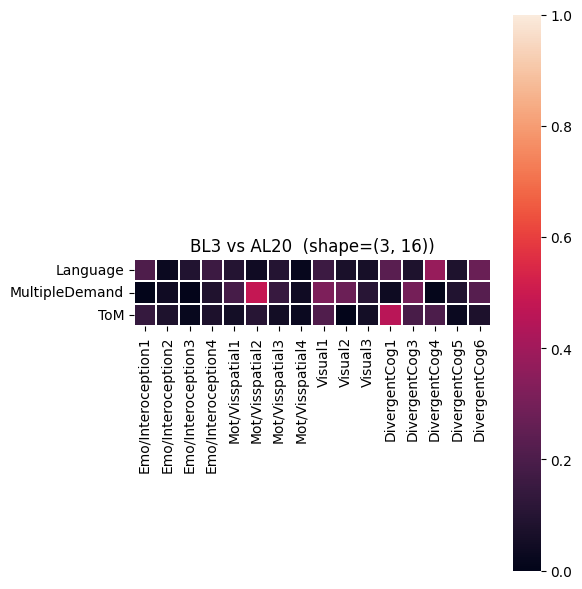

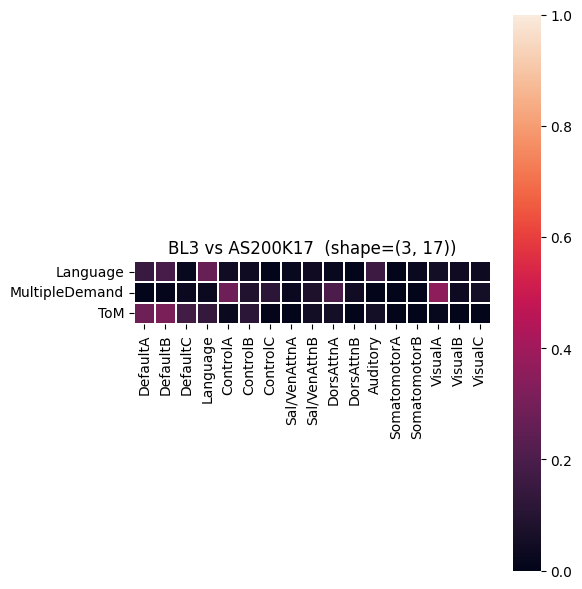

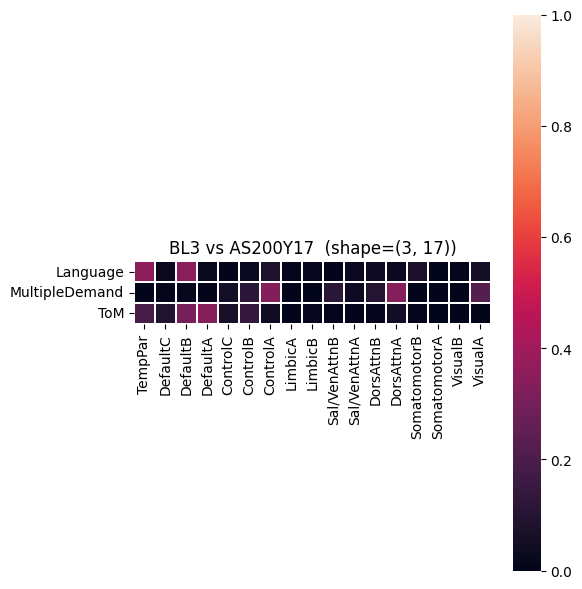

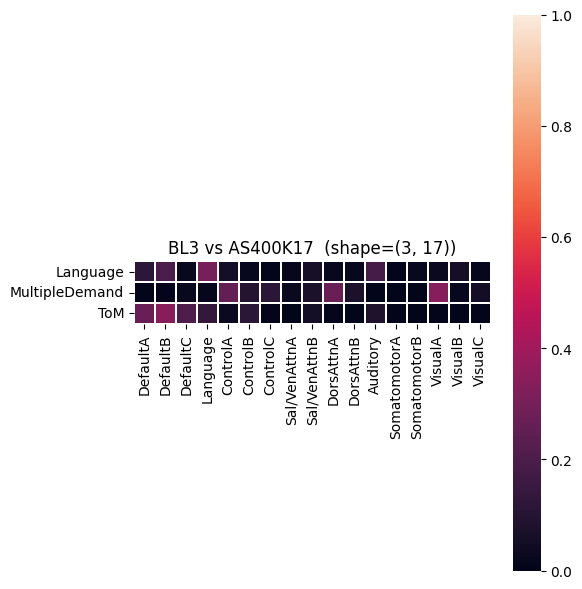

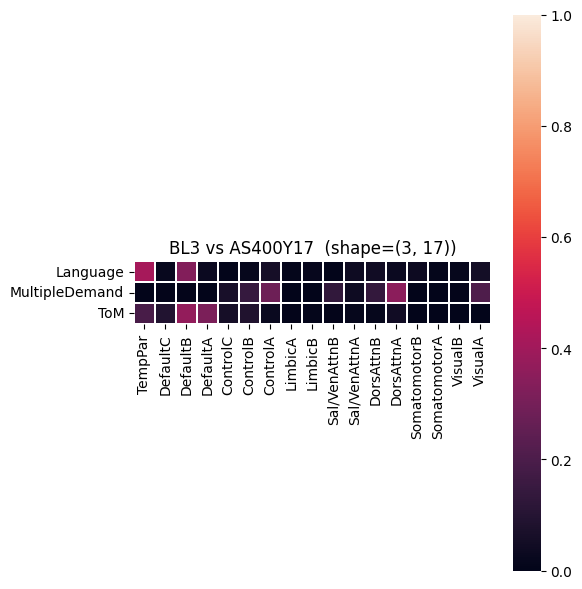

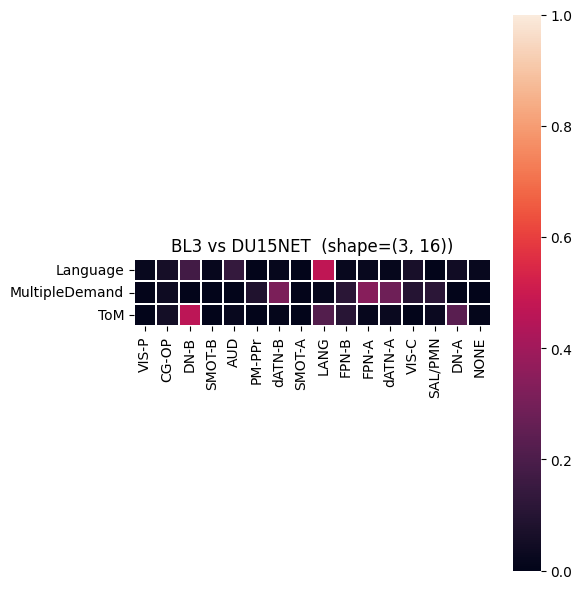

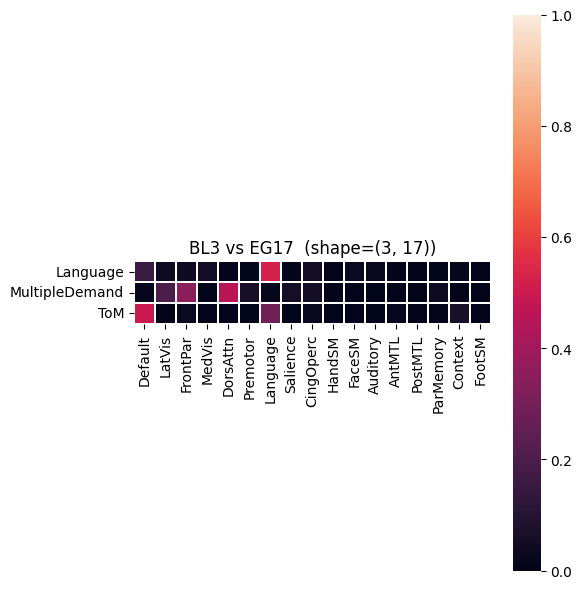

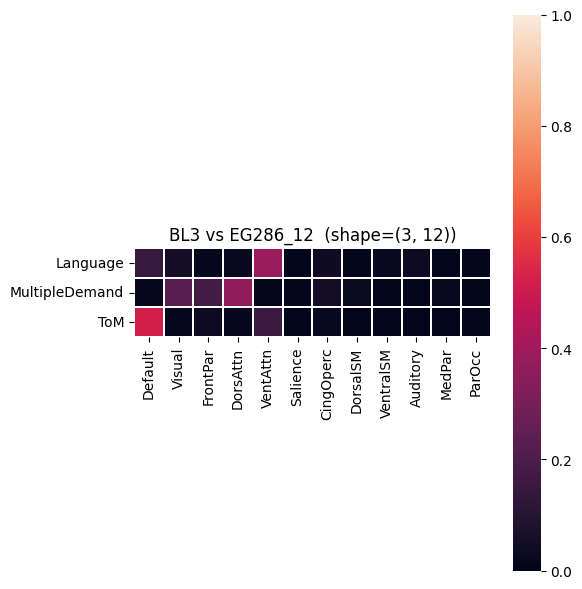

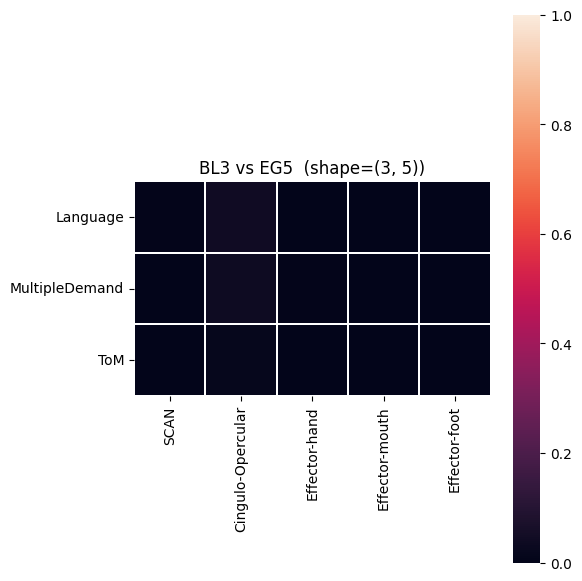

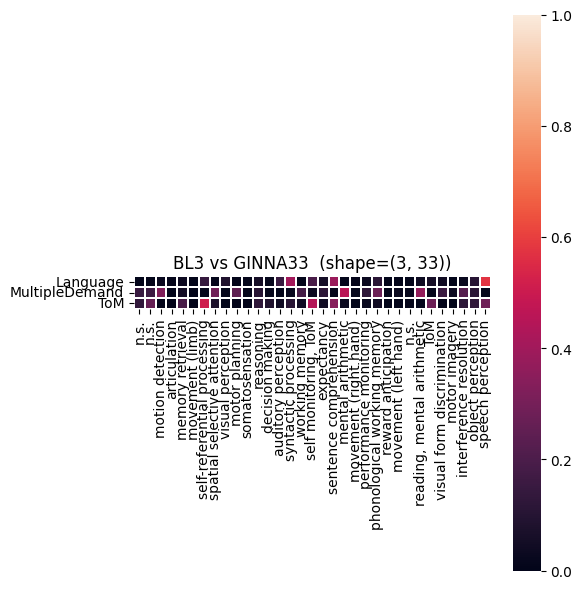

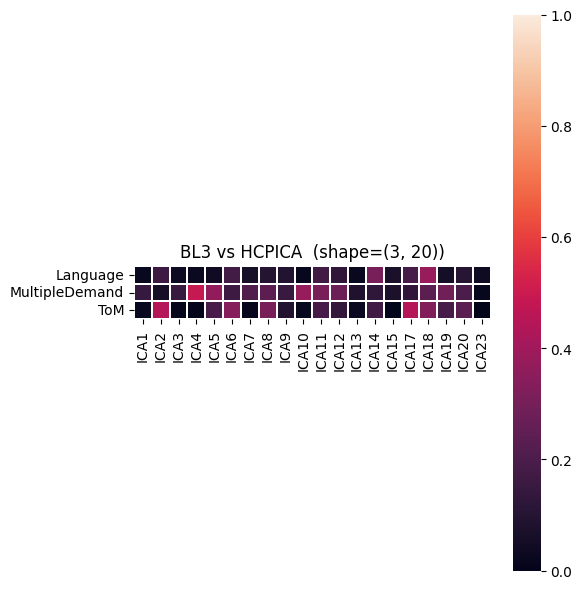

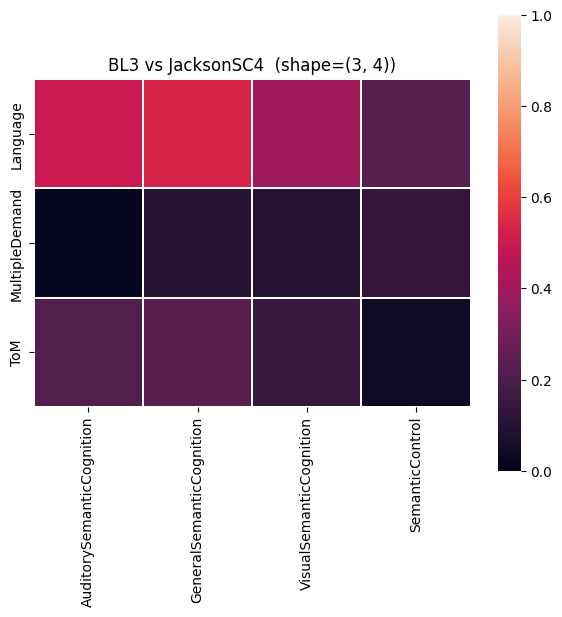

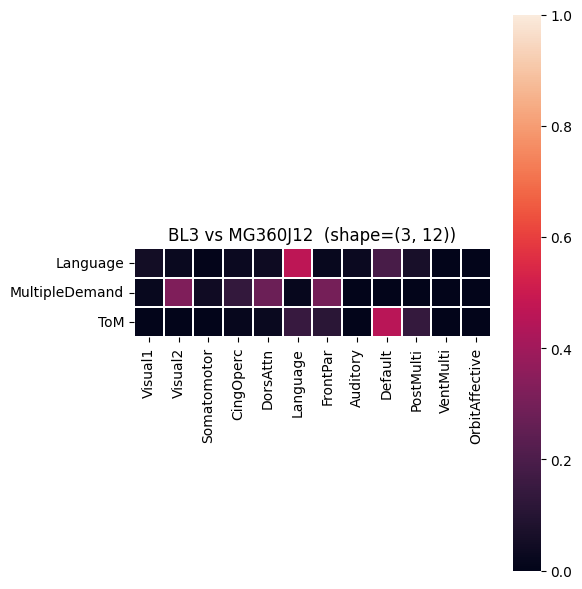

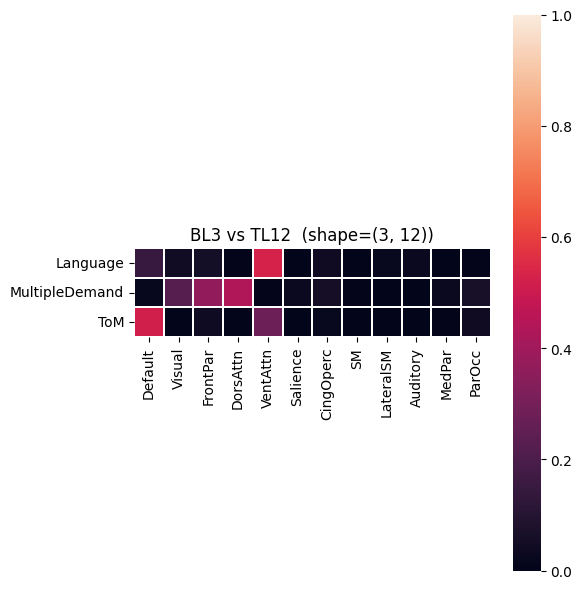

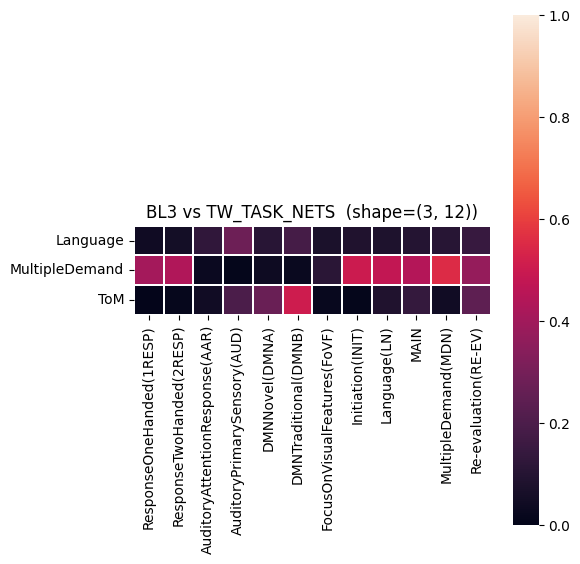

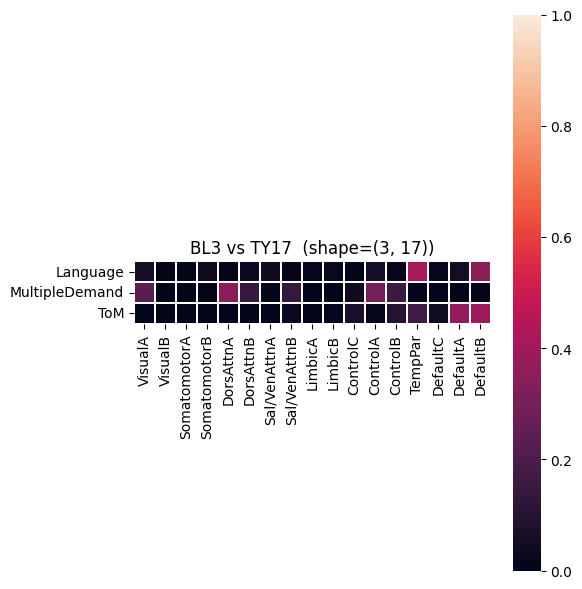

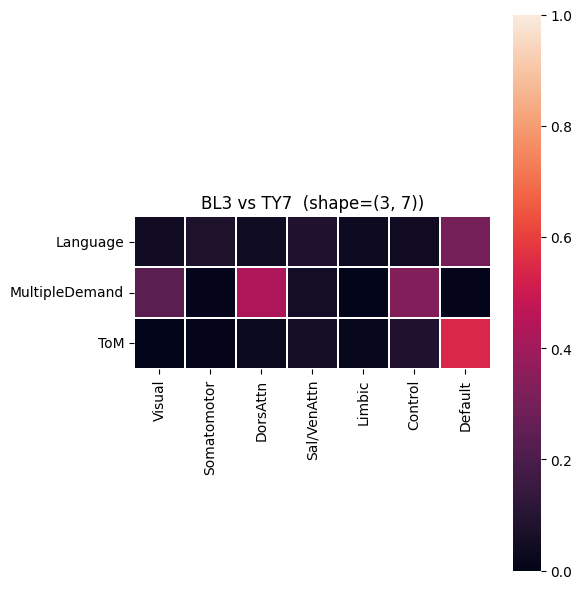

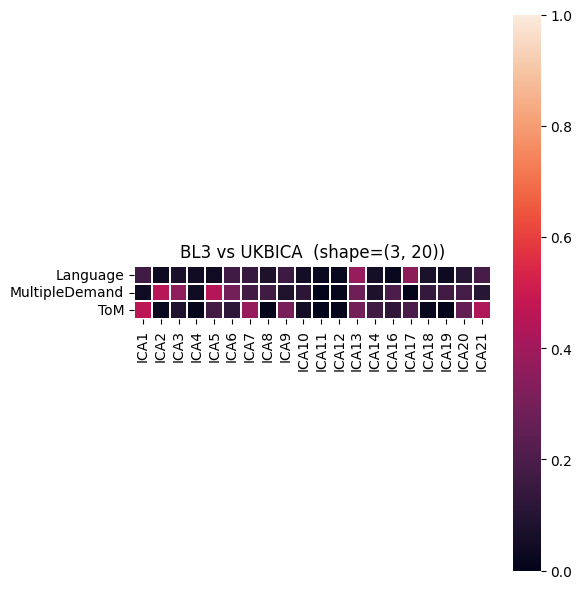

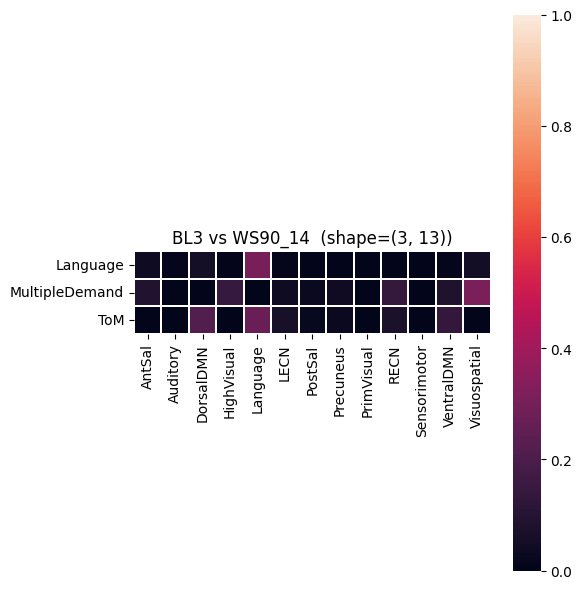

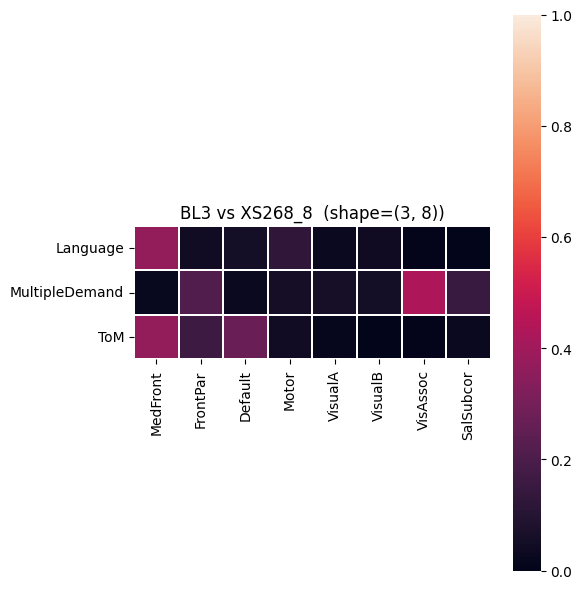

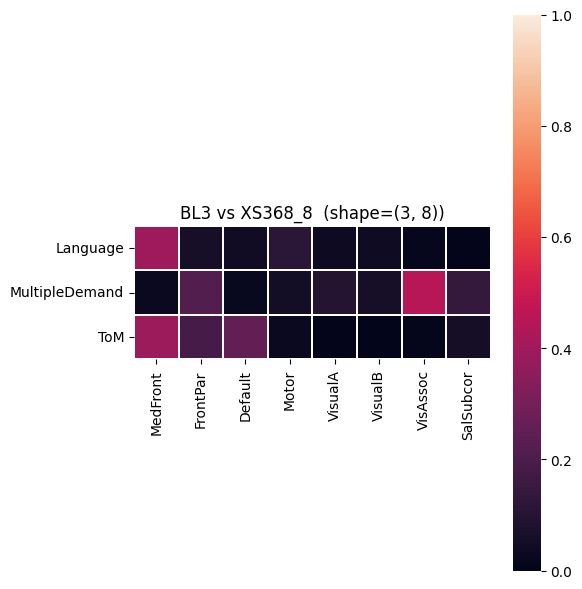

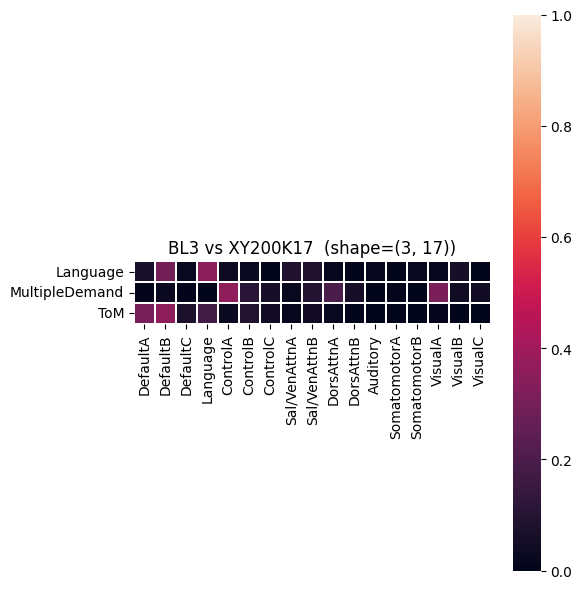

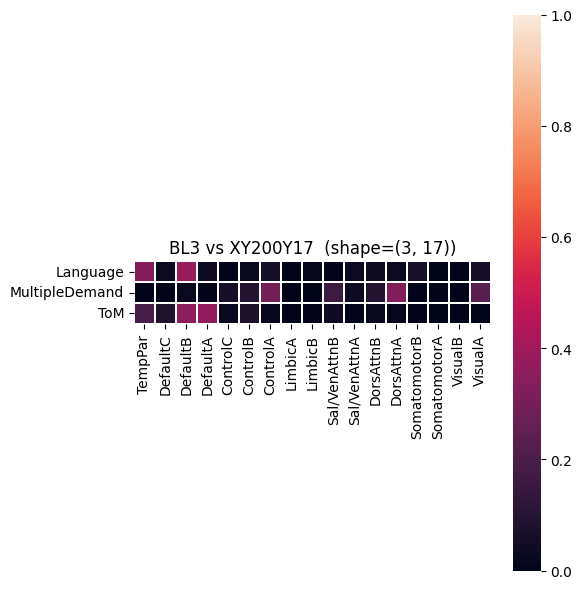

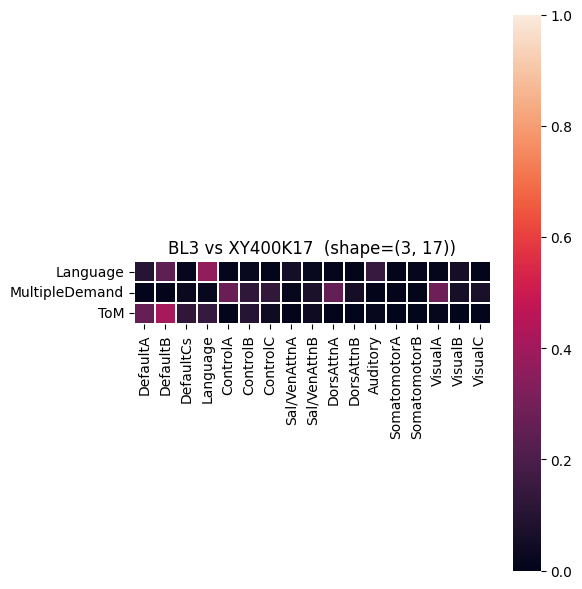

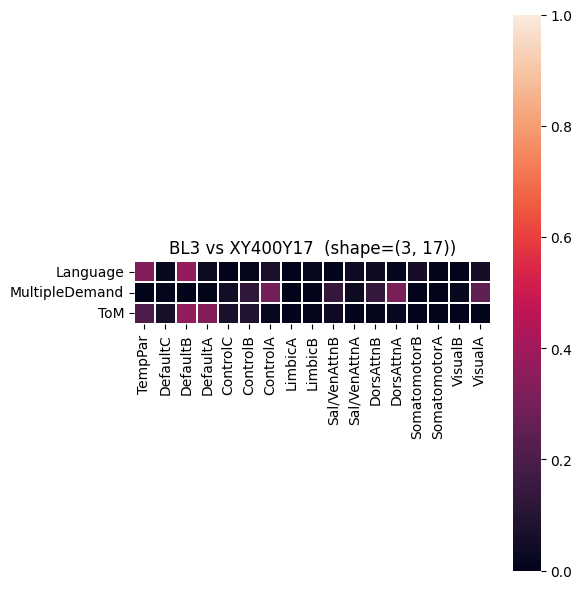

In [8]:
from cbig_network_correspondence import visualize_overlap_lib as vis

overlap_dir = DATA_REPO / "overlap_results" / NEW_ATLAS
mat_files = sorted(overlap_dir.glob("*.mat"))
print(f"{len(mat_files)} computed overlap_results file(s) for {NEW_ATLAS!r} in {overlap_dir}")

for mat_file in mat_files:
    other_atlas = mat_file.stem
    overlap_val = scipy.io.loadmat(mat_file)["overlap"]
    ref_names = vis.construct_network_name(NEW_ATLAS)
    other_names = vis.construct_network_name(other_atlas)

    plt.figure(figsize=(6, 6))
    sns.heatmap(overlap_val, xticklabels=other_names, yticklabels=ref_names,
                cmap="rocket", vmin=0, vmax=1, square=True, linewidth=0.05)
    plt.title(f"{NEW_ATLAS} vs {other_atlas}  (shape={overlap_val.shape})")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()
